In [ ]:
pip install ugot

In [ ]:
import time
from ugot import ugot
got = ugot.UGOT()
got.initialize('192.168.1.180')
print("UGOT connected.")
got.play_audio_tts("Hello,how are you doing?", 0, False)
got.show_light_rgb_effect(0,255,0,3)
time.sleep(2)
got.turn_off_lights()

In [ ]:
Laser1 = got.read_distance_data(21)
Laser2 = got.read_distance_data(51)
print(Laser1)
print(Laser2)


In [ ]:
# OpenCV related import
import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image,display,clear_output
import os

In [ ]:
# YOLO library
import ultralytics
from ultralytics import YOLO
import cv2
from IPython.display import Image, display

ultralytics.checks()
model = YOLO("yolo26n.pt")
print("The model is ready.")

# Level 4 Term 1

## Session 1

1. tuple

In [ ]:
my_friend1 = ["apple",1000,"Mars",True,["red","yellow"]]
my_friend2 = ("apple",1000,"Mars",True,["red","yellow"])
print(my_friend1)
print(my_friend2)
print(type(my_friend1))  # we can change the list
print(type(my_friend2))  # we can NOT change the tuple

2. access tuple

In [ ]:
print(my_friend2[1])
print(my_friend2[4][0])
print(my_friend2[2:4])
print(my_friend2[:3])
print(my_friend2[::2])
print(my_friend2[::-1])

## Session 2

1. unpack tuple

In [ ]:
my_friend2 = ("apple",1000,"Mars",True,["red","yellow"])
name,age,home,handsome,color=my_friend2
print(name,age)
print(age)
print(home)
print(handsome)
print(color)

In [ ]:
my_friend2 = ("apple",1000,"Mars",True,["red","yellow"])
name,*others = my_friend2
print(name)


In [ ]:
my_friend2 = ("apple",1000,"Mars",True,["red","yellow"])
name,*others,home = my_friend2
print(name)
print(color)


In [ ]:
import time
got.load_models(["apriltag_qrcode"])
AP_info = got.get_apriltag_total_info()

while True:
    AP_info = got.get_apriltag_total_info()
    if not AP_info:
        got.mecanum_move_xyz(0,0,30)
    else:
        got.mecanum_stop()
        break
print("I found the apriltag!!!")


2. check point game

In [ ]:
# step 1 Apriltag recognition
import time
got.load_models(["apriltag_qrcode"])
AP_info = got.get_apriltag_total_info()

while True:
    AP_info = got.get_apriltag_total_info()
    if not AP_info:
        got.mecanum_move_xyz(0,0,30)
    else:
        got.mecanum_stop()
        break
print("I found the apriltag!!!")

# Step check point information
while True:
    AP_info = got.get_apriltag_total_info()
    check_point = ("AP_4",3,90,100)  # APID,direction,degrees,distance
    AP_name = f"AP_{AP_info[0][0]}"
    if AP_name == check_point[0]:
        print(f"I found {AP_name}")
        direction = check_point[1]
        degrees = check_point[2]
        distance =check_point[3]
        got.mecanum_turn_speed_times(direction,30,degrees,2)
        got.mecanum_move_speed_times(0,30,distance,1)
        print("Mission completed!!")
        break

## Session 3

1. Dictionary

In [ ]:
my_friend1 = ["Jack",1000,"Mars","Apple",["yellow","blue"]]
my_friend2 = ("Jack",1000,"Mars","Apple",("yellow","blue"))
print(type(my_friend1))
print(type(my_friend2))
print(my_friend2[4][1])

In [ ]:
my_friend3 = {
    "name":"Jack",  # key : value pair
    "age":1000,
    "Birth_place":"Mars",
    "favorite_fruit":"Apple",
    "favorite_color":["yellow","blue"],
}
print(my_friend3)
print(type(my_friend3))

2. access items

In [ ]:
print(my_friend3["name"])
print(my_friend3.keys())
print(my_friend3.values())
print(my_friend3.items())

3.change items

In [ ]:
my_friend3["name"] = "John"  # change an item
my_friend3["favorite_sport"] = "football"   # add an item
my_friend3.pop("favorite_fruit")


In [ ]:
print(my_friend3)

## Session 4

1. loop dictionary

In [ ]:
my_friend4= {
    "name":"Jack",
    "age":1000,
    "birth planet":"Mars",
    "fruit":"apple",
    "color":"blue,yellow",
}

In [ ]:
for i in my_friend4:
    print(i)
for i in my_friend4.values():
    print(i)
for i in my_friend4.items():
    print(i)

In [ ]:
for i,j in my_friend4.items():
    print(i,j)

2. nested dictionaries

In [ ]:
classmate1 = {
    "name":"Alice",
    "age":10,}
classmate2 = {
    "name":"Jack",
    "age":11,}
classmate3 = {
    "name":"John",
    "age":12,}
classmates = {
    "classmate1":classmate1,
    "classmate2":classmate2,
    "classmate3":classmate3,
}

print(classmates)
for i,j in classmates.items():
    print(i,j)
print(classmates["classmate3"]["name"])

3. the laser sensor and dictionary

In [ ]:
import time
Laser1 = got.read_distance_data(21)

ditance = {
    "go":{"range":100,"color":"green"},
    "slow":{"range":20,"color":"blue"},
    "stop":{"range":10,"color":"red"},
}

while True:
    Laser1 = got.read_distance_data(21)
    print(f"The laser sensor value is:{Laser1}")

    if Laser1>distance["go"]["range"]:
        action = "go"
        print("go")
    elif Laser1>distance["slow"]["range"]:
        action = "slow"
        print("slow")
    else:
        action = "stop"
        print("stop")
    if action =="stop":
        break
    time.sleep(0.5)
    

## Session 5

1. voice recognition

In [ ]:
question = got.start_audio_asr()
got.start_audio_nlp(question, True)
print(question)

In [ ]:
while True:
    question = got.start_audio_asr()
    if not question:
        continue
    command = question.lower().strip()
    if "stop" in command:
        print("It's nice talking to you, see you next time!")
        break

    print(f"Your question is:{question}")
    reply = got.start_audio_nlp(question, True)
    print(f"The UGOT reply is:{reply}")

2. changing the color with voice recognition

In [ ]:
colors = {
    "red":(255,0,0),
    "green":(0,255,0),
    "blue":(0,0,255),
    "white":(255,255,255),
    }
print("Please let me know what color you would like me to show?")

while True:
    question = got.start_audio_asr()
    if not question:
        continue

    got.start_audio_nlp(question, False)
    print(question)

    command = question.lower().strip()

    for color,(r,g,b) in colors.items():
        if color in command:
            got.show_light_rgb_effect(r,g,b,3)
            print(f"The light is changed to {color}")
            time.sleep(2)
            break

    if "stop" in command:
        print("It's nice talking to you, see you next time!")
        got.turn_off_lights()
        break

3. voice recognition and chssis control

In [ ]:
movements = {
    "forward":(0,10,0),
    "backward":(0,-10,0),
    "left":(-10,0,0),
    "right":(10,0,0),
    "rotate":(0,0,10),
    }
print("Please let me know how to move.")

while True:
    question = got.start_audio_asr()
    if not question:
        continue

    got.start_audio_nlp(question, False)
    print(question)

    command = question.lower().strip()

    for direction,(x,y,z) in movements.items():
        if direction in command:
            got.mecanum_move_xyz(x,y,z)
            print(f"I am moving {direction}")
            break
    if"stop" in command:
        got.mecanum_stop()
        print("Game over!")
        break

## Session 6

1. Mechanical arm control

In [ ]:
import time
def pick_up():
    got.mechanical_clamp_release()
    time.sleep(1)
    got.mechanical_joint_control(0,30,30,1000)
    time.sleep(1)
    got.mechanical_joint_control(0,0,-75,1000)
    time.sleep(1)
    got.mechanical_clamp_close()
    time.sleep(1)
    got.mechanical_joint_control(0,30,30,1000)
    time.sleep(1)

def put_down():
    got.mechanical_joint_control(-90,0,-80,1000)
    time.sleep(1.5)
    got.mechanical_clamp_release()
    time.sleep(1)
    got.mechanical_joint_control(-90,30,30,1000)
    time.sleep(1)
    got.mechanical_joint_control(0,30,30,1000)
    time.sleep(1)
    got.mechanical_clamp_close()
    time.sleep(1)

def AP_approaching():
    got.load_models(["apriltag_qrcode"])
    AP_info = got.get_apriltag_total_info()

    while True:
        AP_info = got.get_apriltag_total_info()
        AP_x = AP_info[0][1]
        distance = AP_info[0][6]
        if AP_x> 340:
            got.mecanum_move_xyz(5,5,0)
            time.sleep(0.1)
        elif AP_x< 300:
            got.mecanum_move_xyz(-5,5,0)
            time.sleep(0.1)
        elif distance > 0.16:
            got.mecanum_move_xyz(0,5,0)
            time.sleep(0.1)
        else:
            got.mecanum_stop()
            break
    print("It's too close, let's stop!")

In [ ]:
AP_approaching()
pick_up()
put_down()

## Session 7

1. practice

In [ ]:
question = got.start_audio_asr()
reply = got.start_audio_nlp(question, True)
print(question)
print(reply)

In [ ]:
while True:
    question = got.start_audio_asr()
    if not question:
        continue
    command = question.lower().strip()
    if "stop" in command:
        print("It's nice talking to you, see you next time!")
        break
    print(f"Your question is:{question}")
    reply = got.start_audio_nlp(question, True)
    print(f"The UGOT reply is:{reply}")

2. voice recognition and chassis control

In [ ]:
movements = {
    "forward":(0,10,0),
    "backward":(0,-10,0),
    "left":(-10,0,0),
    "right":(0,10,0),
    "rotate":(0,0,10),
}
print("Please tell me how to move.")
while True:
    conversation = got.start_audio_asr()
    if not conversation:
        continue
    command = conversation.lower().strip()
    
    for key,(x,y,z) in movements.items():
        if key in command:
            got.mecanum_move_xyz(x,y,z)
            print(f"I am moving {key}.")
            break
    
    if "stop" in command:
        got.mecanum_stop()
        print("I will stop")
        break

## Session 8

1. AP tage_mechanical arm control

In [ ]:
import time
got.load_models(["apriltag_qrcode"])
AP_info = got.get_apriltag_total_info()
AP_x = AP_info[0][1]
distance = AP_info[0][6]
for i in range(5):
    AP_info = got.get_apriltag_total_info()
    AP_x = AP_info[0][1]
    distance = AP_info[0][6]
    print(f"The value of AP_x is {AP_x},the value of distance is {distance}.")
    

In [ ]:
def pick_up():
    import time
    got.load_models(["apriltag_qrcode"])
    got.mechanical_joint_control(0,30,30, 1000)
    got.mechanical_clamp_release()
    time.sleep(2)

    while True:
        AP_info = got.get_apriltag_total_info()
        if AP_info:
            AP_x = AP_info[0][1]
            distance = AP_info[0][6]
            joint1= int((AP_x-320)*-1/10)
            joint3=int(distance*100-80)
            got.mechanical_clamp_release()
            time.sleep(2)
            got.mechanical_joint_control(joint1,0, joint3, 1000)
            time.sleep(1)
            got.mechanical_clamp_close()
            time.sleep(2)
            got.mechanical_joint_control(0,30,30, 1000)
            time.sleep(2)
        else:
            break

def AP_approaching():
    got.load_models(["apriltag_qrcode"])
    AP_info = got.get_apriltag_total_info()

    while True:
        AP_info = got.get_apriltag_total_info()
        AP_x = AP_info[0][1]
        distance = AP_info[0][6]
        if AP_x> 340:
            got.mecanum_move_xyz(5,5,0)
            time.sleep(0.1)
        elif AP_x< 300:
            got.mecanum_move_xyz(-5,5,0)
            time.sleep(0.1)
        elif distance > 0.16:
            got.mecanum_move_xyz(0,5,0)
            time.sleep(0.1)
        else:
            got.mecanum_stop()
            break
    print("It's too close, let's stop!")

In [ ]:
AP_approaching()
pick_up()

## Session 9

In [ ]:
def voice_recognition():
    movements = {
        "forward":(0,10,0),
        "backward":(0,-10,0),
        "left":(-10,0,0),
        "right":(10,0,0),
        "rotate":(0,0,10),
    }
    print("Please tell me how to move.")
    while True:
        conversation = got.start_audio_asr()
        if not conversation:
            continue
        command = conversation.lower().strip()
        
        for key,(x,y,z) in movements.items():
            if key in command:
                got.mecanum_move_xyz(x,y,z)
                print(f"I am moving {key}.")
                break
        
        if "stop" in command:
            got.mecanum_stop()
            print("I will stop")
            break

def pick_up():
    import time
    got.load_models(["apriltag_qrcode"])
    got.mechanical_joint_control(0,30,30, 1000)
    got.mechanical_clamp_release()
    time.sleep(2)

    while True:
        AP_info = got.get_apriltag_total_info()
        if AP_info:
            AP_x = AP_info[0][1]
            distance = AP_info[0][6]
            joint1= int((AP_x-320)*-1/10)
            joint3=int(distance*100-80)
            got.mechanical_clamp_release()
            time.sleep(2)
            got.mechanical_joint_control(joint1,0, joint3, 1000)
            time.sleep(1)
            got.mechanical_clamp_close()
            time.sleep(2)
            got.mechanical_joint_control(-90,30,30, 1000)
            time.sleep(2)
        else:
            break

def put_down():
    got.mechanical_joint_control(-90,0,-80,1000)
    time.sleep(1.5)
    got.mechanical_clamp_release()
    time.sleep(1)
    got.mechanical_joint_control(-90,30,30,1000)
    time.sleep(1)
    got.mechanical_joint_control(0,30,30,1000)
    time.sleep(1)
    got.mechanical_clamp_close()
    time.sleep(1)

def AP_approaching():
    got.load_models(["apriltag_qrcode"])
    AP_info = got.get_apriltag_total_info()

    while True:
        AP_info = got.get_apriltag_total_info()
        AP_x = AP_info[0][1]
        distance = AP_info[0][6]
        if AP_x> 340:
            got.mecanum_move_xyz(5,5,0)
            time.sleep(0.1)
        elif AP_x< 300:
            got.mecanum_move_xyz(-5,5,0)
            time.sleep(0.1)
        elif distance > 0.16:
            got.mecanum_move_xyz(0,5,0)
            time.sleep(0.1)
        else:
            got.mecanum_stop()
            break
    print("It's too close, let's stop!")

def line_follow():
    import time
    got.load_models(["line_recognition"])
    got.set_track_recognition_line(0)

    line_info = got.get_single_track_total_info()
    line_type = line_info[1]

    while line_type>0:
        line_info = got.get_single_track_total_info()
        line_type = line_info[1]
        offset = line_info[0]
        degrees = int(0.2*offset)
        got.mecanum_move_xyz(0,25,degrees)
        time.sleep(0.1)

    got.mecanum_stop()
    print("I can not see the line.")

In [ ]:
import time
got.mechanical_joint_control(90,30,30,1000)
time.sleep(1)
AP_approaching()
pick_up()
line_follow()
voice_recognition()
put_down()

In [ ]:
def pick_up():
    import time
    got.load_models(["apriltag_qrcode"])
    got.mechanical_joint_control(0,30,30, 1000)
    got.mechanical_clamp_release()
    time.sleep(2)
    AP_info = got.get_apriltag_total_info()
    AP_x = AP_info[0][1]
    distance = AP_info[0][6]
    joint1= int((AP_x-320)*-1/10)
    joint3=int(distance*100-80)
    got.mechanical_clamp_release()
    time.sleep(2)
    got.mechanical_joint_control(joint1,0, joint3, 1000)
    time.sleep(1)
    got.mechanical_clamp_close()
    time.sleep(2)
    got.mechanical_joint_control(-90,30,30, 1000)
    time.sleep(1)

In [ ]:
def pick_up_for_sure():
    import time
    got.load_models(["apriltag_qrcode"])
    AP_info = got.get_apriltag_total_info()

    AP_approaching()
    pick_up()
    time.sleep(2)

    while True:
        AP_info = got.get_apriltag_total_info()
        if AP_info:
            got.mecanum_move_speed_times(1,20,30,1)
            AP_approaching()
            pick_up()
            time.sleep(2)
        else:
            break
    print("Ive pick up the token successuflly!")

In [ ]:
pick_up_for_sure()
got.mecanum_turn_speed_times(3,30,90,2)
AP_approaching()
put_down()

# Level4 Term 2

## Session 1

In [ ]:
pip install opencv-python

In [ ]:
pip install matplotlib

1. download and show an image

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image,display

In [ ]:
dog = cv2.imread("dog.jpg")
print("Shape(H,W,C):",dog.shape)
Image("dog.jpg")



In [ ]:
dog = cv2.imread("dog.jpg")
print("Loaded:",dog is not None)

if dog is not None:
    print("Shape(H,W,C):",dog.shape)
    print("dtype:",dog.dtype)
    print("Top-left pixel(B,G,R):",dog[0,0])

2. Array

In [ ]:
array1D = [1,2,3,4,5,6]
print(array1D)
print(type(array1D))

In [ ]:
array1D = [1,2,3,4,5,6]  # array demands the same data type for the items.
list = ["red",1000,True,("apple","banana")]
print(array1D)
print(type(array1D))
print(list)
print(type(list))

3. Array in Numpy

In [ ]:
import numpy as np
# 1D array
array1D = np.array([1,2,3,4,5,6])
print(f"1D Array: {array1D}")
print(f"Shape:{array1D.shape}")
print(type(array1D))


In [ ]:
# 2D array
array2D = np.array([[1,2,3],
                   [4,5,6]])
print(f"2D Array: {array2D}")
print(f"Shape:{array2D.shape}")
print(type(array2D))

In [ ]:
# 3D array
array3D = np.array([[[255,0,0],[0,255,0],[0,0,255]],
                    [[0,0,255],[0,255,0],[255,0,0]]])
print(f"3D Array: {array3D}")
print(f"Shape:{array3D.shape}")
print(type(array3D))

In [ ]:
array3D = np.array([[[255,0,0],[0,255,0],[0,0,255],[0,255,0],[0,0,255],[0,0,255],[0,0,255]],
                    [[255,0,0],[0,255,0],[0,0,255],[0,255,0],[0,0,255],[0,0,255],[0,0,255]],
                    [[255,0,0],[0,255,0],[0,0,255],[0,255,0],[0,0,255],[0,0,255],[0,0,255]],
                    [[255,0,0],[0,255,0],[0,0,255],[0,255,0],[0,0,255],[0,0,255],[0,0,255]],
                    [[255,0,0],[0,255,0],[0,0,255],[0,255,0],[0,0,255],[0,0,255],[0,0,255]],
                    [[255,0,0],[0,255,0],[0,0,255],[0,255,0],[0,0,255],[0,0,255],[0,0,255]]])
print(f"3D Array: {array3D}")
print(f"Shape:{array3D.shape}")
print(type(array3D))

In [ ]:
Image("Array.png")

## Session 2

1. PID control

In [ ]:
Image("PID.png")

In [ ]:
while True:
    Laser1 = got.read_distance_data(21)
    if Laser1>10:
        got.mecanum_move_speed(0,20)
    else:
        got.mecanum_stop()
        break

In [ ]:
# deceleration challenge
while True:
    Laser1 = got.read_distance_data(21)
    if Laser1>50:
        got.mecanum_move_speed(0,50)
    elif Laser1>10:
        got.mecanum_move_speed(0,int(Laser1))
    else:
        got.mecanum_stop()
        break

In [ ]:
# Proportional control
import time
safe_distance = 10
Kp = 0.8

while True:
    current_distance = got.read_distance_data(21)

    error = current_distance - safe_distance
    print(f"The error is : {error}.")

    if abs(error) < 1:
        got.mecanum_stop()
        break
    
    speed = Kp * error
    print(f"The speed is : {speed}.")
    speed = min(speed,40)

    got.mecanum_move_speed(0,int(speed))
    time.sleep(0.05)

In [ ]:
# Proportional + integral control
import time
safe_distance = 10
Kp = 0.8
Ki = 0.2

total_error = 0

while True:
    current_distance = got.read_distance_data(21)

    error = current_distance - safe_distance
    print(f"The error is : {error}.")

    if abs(error) < 1:
        got.mecanum_stop()
        break
    
    total_error += error
    total_error = max(min(total_error,100),-100)
    print(f"The total_error value is: {total_error}")

    speed = Kp * error + Ki *total_error
    print(f"The speed is : {speed}.")
    speed = min(speed,40)

    got.mecanum_move_speed(0,int(speed))
    time.sleep(0.05)


In [ ]:
# Proportional + Integral + Derivative control
import time
safe_distance = 10
Kp = 0.8
Ki = 0.2
Kd = 0.3

total_error = 0
previous_error = 0

while True:
    current_distance = got.read_distance_data(21)

    error = current_distance - safe_distance
    print(f"The error is : {error}.")

    if abs(error) < 1:
        got.mecanum_stop()
        break
    
    total_error += error
    total_error = max(min(total_error,100),-100)
    print(f"The total_error value is: {total_error}")

    derivative = error - previous_error

    speed = Kp * error + Ki *total_error + Kd* derivative
    print(f"The speed is : {speed}.")
    speed = min(speed,40)

    previous_error = error
    got.mecanum_move_speed(0,int(speed))
    time.sleep(0.05)


In [ ]:
ok,picture_jpg = cv2.imencode(".jpg",picture)
got.open_camera()
display(Image(picture_jpg.tobytes()))
picture = np.frombuffer(picture,np.uint8)
picture = got.read_camera_data()
picture = cv2.imdecode(picture,cv2.IMREAD_COLOR)

## Session 3

1. UGOT image display

In [ ]:
# Step 1: trun on the camera
got.open_camera()
print("The camera is on.")

# Step 2: get the raw data
picture = got.read_camera_data()
print(f"The raw data:{picture}.")
print(f"Data type:{type(picture)}")

# Step 3: unpack the raw data, bytes to 1D array
picture = np.frombuffer(picture,np.uint8)
print(f"The data:{picture}.")
print(f"Shape:{picture.shape}")
print(f"Data type:{type(picture)}")

# Step 4: 1D array to 3D array
picture = cv2.imdecode(picture,cv2.IMREAD_COLOR)
print(f"The data:{picture}.")
print(f"Shape:{picture.shape}")
print(f"Data type:{type(picture)}")

# Step 5: pack 3D array for Jupyter
ok,picture_jpg = cv2.imencode(".jpg",picture)
print(f"The data:{picture}.")
print(f"Shape:{picture.shape}")
print(f"Data type:{type(picture)}")

# Step 6: Show the image on screen
display(Image(picture_jpg.tobytes()))

In [ ]:
Image("Robot camera to image-2.png")

In [ ]:

print("The camera is on.")
ok,picture_jpg = cv2.imencode(".jpg",picture_bgr)
picture_1D = np.frombuffer(picture_raw,np.uint8)
picture_raw = got.read_camera_data()
got.open_camera()
display(Image(picture_jpg.tobytes()))
picture_bgr = cv2.imdecode(picture_1D,cv2.IMREAD_COLOR)  


In [ ]:
got.open_camera()
print("The camera is on.")
picture_raw = got.read_camera_data()
picture_1D = np.frombuffer(picture_raw,np.uint8)
picture_bgr = cv2.imdecode(picture_1D,cv2.IMREAD_COLOR)  
ok,picture_jpg = cv2.imencode(".jpg",picture_bgr)
display(Image(picture_jpg.tobytes()))

2. images to video

In [ ]:
import cv2
import numpy as np
from IPython.display import Image,display,clear_output

got.open_camera()
print("The camera is on.")

for i in range(100):
    picture = got.read_camera_data()

    if picture is None:
        continue
    
    picture = np.frombuffer(picture_raw,np.uint8)
    picture = cv2.imdecode(picture,cv2.IMREAD_COLOR)  
    ok,picture_jpg = cv2.imencode(".jpg",picture)
    display(Image(picture_jpg.tobytes()))
    clear_output(True)
    time.sleep(0.01)

In [ ]:
import numpy as np
import cv2
from IPython.display import clear_output,display, Image

got.open_camera()
print("The camera is on.")

for i in range(100):
    picture = got.read_camera_data()

    if picture is None:
        continue

    picture  = np.frombuffer(picture,np.uint8)
    picture = cv2.imdecode(picture,cv2.IMREAD_COLOR)
    ok,picture_jpg = cv2.imencode(".jpg",picture)
    display(Image(picture_jpg.tobytes()))
    clear_output(True)

In [ ]:
import time
import cv2
import numpy as np
from IPython.display import Image,display,clear_output

got.open_camera()
print("The camera is on.")

while True:
    Laser1 = got.read_distance_data(21)
    picture = got.read_camera_data()

    if Laser1 > 50:
        got.show_light_rgb_effect(0,255,0,3)
        time.sleep(0.1)
    
    else:
        if picture is None:
            continue

        picture  = np.frombuffer(picture,np.uint8)
        picture = cv2.imdecode(picture,cv2.IMREAD_COLOR)
        ok,picture_jpg = cv2.imencode(".jpg",picture)
        display(Image(picture_jpg.tobytes()))
        got.show_light_rgb_effect(255,0,0,3)
        time.sleep(3)
        got.turn_off_lights()
        got.play_audio_tts("Gotcha,ha ha ha",0,False)
        break


## Session 4

In [ ]:
import numpy as np
import cv2
from IPython.display import display, Image


print("The camera is on.")
ok,picture_jpg = cv2.imencode(".jpg",picture_bgr)
picture_1D = np.frombuffer(picture_raw,np.uint8)
picture_raw = got.read_camera_data()
got.open_camera()
display(Image(picture_jpg.tobytes()))
picture_bgr = cv2.imdecode(picture_1D,cv2.IMREAD_COLOR)  


In [ ]:
import numpy as np
import cv2
from IPython.display import display, Image

got.open_camera()
print("The camera is on.")
picture_raw = got.read_camera_data()
picture_1D = np.frombuffer(picture_raw,np.uint8)
picture_bgr = cv2.imdecode(picture_1D,cv2.IMREAD_COLOR)  


ok,picture_jpg = cv2.imencode(".jpg",picture_bgr)
display(Image(picture_jpg.tobytes()))

## Session 5

1. BGR to HSV

In [ ]:
import numpy as np
import cv2
from IPython.display import display, Image

got.open_camera()
print("The camera is on.")
picture_raw = got.read_camera_data()

if picture_raw is None:
    raise Exception("No camera data found.")

picture_1D = np.frombuffer(picture_raw,np.uint8)
picture_bgr = cv2.imdecode(picture_1D,cv2.IMREAD_COLOR)  
if picture_bgr is None:
    raise Exception("Imdecode failed, please check the camera or data.")

# convert BGR to HSV
picture_hsv = cv2.cvtColor(picture_bgr,cv2.COLOR_BGR2HSV)

ok,picture_hsv = cv2.imencode(".jpg",picture_hsv)
display(Image(picture_hsv.tobytes()))

In [ ]:
Image("Color wheel.png")

In [ ]:
Image("BGR2HSV.png")

2. make a mask

In [ ]:
import numpy as np
import cv2
from IPython.display import display, Image

got.open_camera()
print("The camera is on.")
picture_raw = got.read_camera_data()

if picture_raw is None:
    raise Exception("No camera data found.")

picture_1D = np.frombuffer(picture_raw,np.uint8)
picture_bgr = cv2.imdecode(picture_1D,cv2.IMREAD_COLOR)  
if picture_bgr is None:
    raise Exception("Imdecode failed, please check the camera or data.")

# convert BGR to HSV
picture_hsv = cv2.cvtColor(picture_bgr,cv2.COLOR_BGR2HSV)

# Detect the color
lower_color = np.array([85,150,60])
upper_color = np.array([120,255,170])

# Create a mask-greenonly pixel
mask = cv2.inRange(picture_hsv,lower_color,upper_color)

# Show the black-white image
ok,mask = cv2.imencode(".jpg",mask)
display(Image(mask.tobytes()))

## Session 5

1. color only mask

In [ ]:
import numpy as np
import cv2
from IPython.display import display, Image

got.open_camera()
print("The camera is on.")
picture_raw = got.read_camera_data()

if picture_raw is None:
    raise Exception("No camera data found.")

picture_1D = np.frombuffer(picture_raw,np.uint8)
picture_bgr = cv2.imdecode(picture_1D,cv2.IMREAD_COLOR)  
if picture_bgr is None:
    raise Exception("Imdecode failed, please check the camera or data.")

# convert BGR to HSV
picture_hsv = cv2.cvtColor(picture_bgr,cv2.COLOR_BGR2HSV)

# Detect the color
lower_color = np.array([85,150,60])
upper_color = np.array([120,255,170])

# Create a mask-only pixel
mask = cv2.inRange(picture_hsv,lower_color,upper_color)

# show the color image
color_only = cv2.bitwise_and(picture_bgr,picture_bgr,mask = mask)

# Show the color only image
ok,color_only = cv2.imencode(".jpg",color_only)
display(Image(color_only.tobytes()))

In [ ]:
Image("Yellow only.png")

2. bounding box

In [ ]:
import numpy as np
import cv2
from IPython.display import display, Image

got.open_camera()
print("The camera is on.")
picture_raw = got.read_camera_data()

if picture_raw is None:
    raise Exception("No camera data found.")

picture_1D = np.frombuffer(picture_raw,np.uint8)
picture_bgr = cv2.imdecode(picture_1D,cv2.IMREAD_COLOR)  
if picture_bgr is None:
    raise Exception("Imdecode failed, please check the camera or data.")

# convert BGR to HSV
picture_hsv = cv2.cvtColor(picture_bgr,cv2.COLOR_BGR2HSV)

# Detect the color
lower_color = np.array([85,150,60])
upper_color = np.array([120,255,170])

# Create a color-mask-only pixel
mask = cv2.inRange(picture_hsv,lower_color,upper_color)

# find contours(outlines of the white area in the mask)
contours,_ = cv2.findContours(mask,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)

# loop through contours, draw bounding box and label
for contour in contours:
    area = cv2.contourArea(contour)
    if area >500:
        x,y,w,h = cv2.boundingRect(contour)
        cv2.rectangle(picture_bgr,(x,y),(x+w,y+h),(0,255,0),4)
        # label stays inside the loop so every box gets its own text
        cv2.putText(picture_bgr,"Blue Cube",(x,max(30,y-10)),cv2.FONT_HERSHEY_COMPLEX,0.6,(0,255,0),2)

# Show the image with bounding box
ok,picture_jpg = cv2.imencode(".jpg",picture_bgr)
if ok:
    display(Image(picture_jpg.tobytes()))
else:
    print("Encoding failed.")

In [ ]:
import numpy as np
import cv2
from IPython.display import display, Image

got.open_camera()
print("The camera is on.")
picture_raw = got.read_camera_data()

if picture_raw is None:
    raise Exception("No camera data found.")

picture_1D = np.frombuffer(picture_raw,np.uint8)
picture_bgr = cv2.imdecode(picture_1D,cv2.IMREAD_COLOR)  
if picture_bgr is None:
    raise Exception("Imdecode failed, please check the camera or data.")

# convert BGR to HSV
picture_hsv = cv2.cvtColor(picture_bgr,cv2.COLOR_BGR2HSV)

# Detect the color
lower_color = np.array([85,150,60])
upper_color = np.array([120,255,170])

# Create a color-mask-only pixel
mask = cv2.inRange(picture_hsv,lower_color,upper_color)

# find contours(outlines of the white area in the mask)
contours,_ = cv2.findContours(mask,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)

# loop through contours and draw bounding box
for contour in contours:
    area = cv2.contourArea(contour)
    if area >500:
        x,y,w,h = cv2.boundingRect(contour)
        cv2.rectangle(picture_bgr,(x,y),(x+w,y+h),(0,255,0),4)

# label the bounding box
cv2.putText(picture_bgr,"Blue Cube",(x,y-10),cv2.FONT_HERSHEY_COMPLEX,0.6,(0,255,0),2)

# Show the color only image with bounding box
ok,picture_bgr = cv2.imencode(".jpg",picture_bgr)
display(Image(picture_bgr.tobytes()))

3. UGOT camera color picker

In [ ]:
import numpy as np
import cv2
from IPython.display import display, Image

got.open_camera()
print("The camera is on.")
picture_raw = got.read_camera_data()

if picture_raw is None:
    raise Exception("No camera data found.")

picture_1D = np.frombuffer(picture_raw,np.uint8)
picture_bgr = cv2.imdecode(picture_1D,cv2.IMREAD_COLOR)  
if picture_bgr is None:
    raise Exception("Imdecode failed, please check the camera or data.")

# convert BGR to HSV
picture_hsv = cv2.cvtColor(picture_bgr,cv2.COLOR_BGR2HSV)

# get the picture size
height = picture_hsv.shape[0]
width = picture_hsv.shape[1]

# find the center point
center_x = width//2
center_y = height//2

# read the HSV value, show the value with the command
h = picture_hsv[center_y,center_x,0]  # h = hue(color)
s = picture_hsv[center_y,center_x,1]  # s = saturation(how vivid)
v = picture_hsv[center_y,center_x,2]  # v = value(brightness)

print(f"H = {h}")
print(f"S = {s}")
print(f"V = {v}")

# draw a small circle at the center of the image
cv2.circle(picture_bgr,(center_x,center_y),8,(0,255,0),2)

# show the image with the circle
ok,picture_bgr = cv2.imencode(".jpg",picture_bgr)
display(Image(picture_bgr.tobytes()))

In [ ]:
import numpy as np
import cv2
from IPython.display import display, Image

got.open_camera()
print("The camera is on.")
picture_raw = got.read_camera_data()


if picture_raw is None:
    raise Exception("No camera data found.")

picture_1D = np.frombuffer(picture_raw,np.uint8)
picture_bgr = cv2.imdecode(picture_1D,cv2.IMREAD_COLOR)  
if picture_bgr is None:
    raise Exception("Imdecode failed, please check the camera or data.")

# convert BGR to HSV
picture_hsv = cv2.cvtColor(picture_bgr,cv2.COLOR_BGR2HSV)

# Detect the color
lower_color = np.array([0,190,170])
upper_color = np.array([40,255,255])

# Create a color-mask-only pixel
mask = cv2.inRange(picture_hsv,lower_color,upper_color)

# find contours(outlines of the white area in the mask)
contours,_ = cv2.findContours(mask,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)

# loop through contours and draw bounding box
for contour in contours:
    area = cv2.contourArea(contour)
    if area >500:
        x,y,w,h = cv2.boundingRect(contour)
        cv2.rectangle(picture_bgr,(x,y),(x+w,y+h),(0,255,0),4)

# label the bounding box
cv2.putText(picture_bgr,"colored object",(x,y-10),cv2.FONT_HERSHEY_COMPLEX,0.6,(0,255,0),2)

# Show the color only image with bounding box
ok,picture_bgr = cv2.imencode(".jpg",picture_bgr)
display(Image(picture_bgr.tobytes()))

## Session 6

1. live video color picker

In [ ]:
import time
import numpy as np
import cv2
from IPython.display import display, Image

got.open_camera()
print("The camera is on.")

dummy = np.zeros((240,320,3),np.uint8)
ok,jpg = cv2.imencode(".jpg",dummy)
handle = display(Image(data = jpg.tobytes()),display_id = True)

start_time = time.time()
duration = 10

while time.time()- start_time < duration:
    picture_raw = got.read_camera_data()
    if picture_raw is None:
        raise Exception("No camera data found.")

    picture_1D = np.frombuffer(picture_raw,np.uint8)
    picture_bgr = cv2.imdecode(picture_1D,cv2.IMREAD_COLOR)  
    if picture_bgr is None:
        raise Exception("Imdecode failed, please check the camera or data.")

    # convert BGR to HSV
    picture_hsv = cv2.cvtColor(picture_bgr,cv2.COLOR_BGR2HSV)

    # get the picture size
    height = picture_hsv.shape[0]
    width = picture_hsv.shape[1]

    # find the center point
    center_x = width//2
    center_y = height//2

    # read the HSV value, show the value with the command
    h = picture_hsv[center_y,center_x,0]  # h = hue(color)
    s = picture_hsv[center_y,center_x,1]  # s = saturation(how vivid)
    v = picture_hsv[center_y,center_x,2]  # v = value(brightness)

    # draw a small circle at the center of the image
    cv2.circle(picture_bgr,(center_x,center_y),8,(0,255,0),2)

    # show HSV value on screen
    text = f"H = {h}, S={s}, V={v}"
    cv2.putText(picture_bgr,text,(10,30),cv2.FONT_HERSHEY_COMPLEX,0.6,(0,255,0),2)

    # Encode ahd update display
    ok,jpg = cv2.imencode(".jpg",picture_bgr)
    if ok:
        handle.update(Image(data = jpg.tobytes()))
    time.sleep(0.05)

print("Time out")

2. bounding box with x,w

In [ ]:
import time
import numpy as np
import cv2
from IPython.display import display, Image

got.open_camera()
print("The camera is on.")

picture_raw = got.read_camera_data()
picture_1D = np.frombuffer(picture_raw,np.uint8)
picture_bgr = cv2.imdecode(picture_1D,cv2.IMREAD_COLOR) 

ok,jpg = cv2.imencode(".jpg",picture_bgr)
handle = display(Image(data = jpg.tobytes()),display_id = True)

lower_color = np.array([0,190,170])
upper_color = np.array([40,255,255])

start_time = time.time()
duration = 10

while time.time()- start_time < duration:
    picture_raw = got.read_camera_data()
    if picture_raw is None:
        raise Exception("No camera data found.")

    picture_1D = np.frombuffer(picture_raw,np.uint8)
    picture_bgr = cv2.imdecode(picture_1D,cv2.IMREAD_COLOR)  
    if picture_bgr is None:
        raise Exception("Imdecode failed, please check the camera or data.")

    # convert BGR to HSV
    picture_hsv = cv2.cvtColor(picture_bgr,cv2.COLOR_BGR2HSV)

    # Create a color-mask-only pixel
    mask = cv2.inRange(picture_hsv,lower_color,upper_color)

    # find contours(outlines of the white area in the mask)
    contours,_ = cv2.findContours(mask,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)

    # loop through contours and draw bounding box
    for contour in contours:
        area = cv2.contourArea(contour)
        if area >500:
            x,y,w,h = cv2.boundingRect(contour)
            # center of bounding box
            center_x = x + w//2
            # draw bounding box
            cv2.rectangle(picture_bgr,(x,y),(x+w,y+h),(0,255,0),4)
            # draw the center point
            cv2.circle(picture_bgr,(center_x,y + h//2),5,(255,0,0),-1)
            # showing x,y,w,h and the center
            text = f"cx:{center_x},w:{w},h:{h}"
            # keep the text visble
            text_y = max(30, y-10)
            # Draw text
            cv2.putText(picture_bgr,text,(x,text_y),cv2.FONT_HERSHEY_COMPLEX,0.6,(0,255,0),2)

    # Encode ahd update display
    ok,jpg = cv2.imencode(".jpg",picture_bgr)
    if ok:
        handle.update(Image(data = jpg.tobytes()))
    time.sleep(0.05)

print("Time out")

# Level 4 Term 3

## Session 1

In [ ]:
while True:
    Laser1 = got.read_distance_data(21)
    if Laser1>10:
        got.mecanum_move_speed(0,20)
    else:
        got.mecanum_stop()
        break

print("It's too close, let's stop")


In [ ]:
Laser1 = got.read_distance_data(21)

while Laser1>10:
    Laser1 = got.read_distance_data(21)
    got.mecanum_move_speed(0,20)

got.mecanum_stop()
print("It's too close, let's stop")


In [ ]:
while True:
    Laser1 = got.read_distance_data(21)

    if Laser1< 10:
        got.mecanum_stop()
        break

    speed = Laser1
    if Laser1>50:
        got.mecanum_move_speed(0,50)
    else: 
        got.mecanum_move_speed(0,int(speed))
        


In [ ]:
while True:
    laser1 = got.read_distance_data(21)

    if laser1 < 10:
        got.mecanum_stop()
        break
    got.mecanum_move_speed(0, int(min(laser1, 50)))

In [ ]:
try:
    while True:
        laser1 = got.read_distance_data(21)

        if laser1 < 10:
            got.mecanum_stop()
            break

        got.mecanum_move_speed(0, int(min(laser1, 50)))

except KeyboardInterrupt:
    got.mecanum_stop()
    print("Stopped by user.")

## Session 2

1. KNN

In [ ]:
Image("KNN.png")

2. mystery fruit

In [ ]:
import random

# 1. Known fruits: [weight, sweetness, name]
fruits = [
    [150, 8, "watermelon"],
    [160, 9, "watermelon"],
    [50, 2, "apple"],
    [30, 2, "apple"]
]

# 2. Create a mystery fruit
mystery_weight = random.randint(30, 150)
mystery_sweetness = random.randint(2, 10)

print(
    f"Mystery fruit found! Weight: {mystery_weight} g, "
    f"Sweetness: {mystery_sweetness}/10"
)

k = int(input("Please enter K: 1 or 3: "))

# 3. Calculate the distance to every known fruit
scored_fruits = []

for fruit in fruits:
    distance = abs(mystery_weight - fruit[0]) + abs(mystery_sweetness - fruit[1])

    # Save: [distance, fruit name]
    scored_fruits.append([distance, fruit[2]])

# 4. Put the closest fruits first
scored_fruits.sort()

# Pick the first K closest fruits
closest_neighbours = scored_fruits[:k]

# 5. Collect the votes
votes = []

for neighbour in closest_neighbours:
    votes.append(neighbour[1])

print(f"Nearest neighbours: {votes}")

# 6. Count the two types of vote
apple_votes = votes.count("apple")
watermelon_votes = votes.count("watermelon")

print(f"Apple votes: {apple_votes}")
print(f"Watermelon votes: {watermelon_votes}")

# 7. Make the final prediction
if watermelon_votes > apple_votes:
    prediction = "watermelon"
else:
    prediction = "apple"

print(f"Prediction: It is probably a {prediction}!")

## Session 3

1. Manhattan distance

In [ ]:
Image("Manhattan distance.png")

In [ ]:
import random

taxi_row = random.randint(0,5)
taxi_col = random.randint(0,5)

passenger_row = random.randint(0,5)
passenger_col = random.randint(0,5)

print(f"Drive the taxi from({taxi_row},{taxi_col}) to the passenger at({passenger_row},{passenger_col})")

moves = 0
while(taxi_row, taxi_col) != (passenger_row,passenger_col):
    move = input("Moves: ")

    if move == "q":
        print("Game over!")
        break
    elif move == "w":
        taxi_row +=1
    elif move == "s":
        taxi_row -=1
    elif move == "a":
        taxi_col -= 1
    elif move == "d":
        taxi_col +=1
    
    moves += 1
    distance = abs(taxi_row - passenger_row) + abs(taxi_col - passenger_col)
    print(f"Taxi now at({taxi_row},{taxi_col}). Distance left: {distance} .")

if (taxi_row, taxi_col) == (passenger_row,passenger_col):
    print(f"You reached the passenger in {moves} steps, good job!")

2. choose the closest passenger

In [ ]:
# .index()

names =["John","Timmy","Ryan"]
scores = [99,60,85]

choice = "Timmy"
chosen_index = names.index(choice)
print(f"Timmy's match score is: {scores[chosen_index]}")

In [ ]:
import random

# The taxi's location
taxi_row = random.randint(0,5)
taxi_col = random.randint(0,5)

# Three passengers: A,B,C
names = ["A","B","C","D","E"]
passengers = []
for i in range(5):
    row = random.randint(0,5)
    col = random.randint(0,5)
    passengers.append((row,col))

print(f"Taxi is at({taxi_row},{taxi_col})")

# calculate the Manhatten distance between the taxi and the passenger
distances = []
for i in range(5):
    p_row,p_col = passengers[i]
    distance = abs(taxi_row - p_row) + abs(taxi_col - p_col)
    distances.append(distance)
    print(f"Passenger{names[i]} is waiting at ({p_row},{p_col}).")

# you should choose which passenger to pick up.
choice = input("Which passenger should the taxi pick up?(A,B,C): ").strip().upper()

while choice not in names:
    choice = input("Please type A,B or C !").strip().upper()

# check whether the chosen passenger is the nearest one.
shorest_distance = min(distances)
chosen_index = names.index(choice)
chosen_distance = distances[chosen_index]

if chosen_distance == shorest_distance:
    print(f"Good job! {choice} is the newarest, only {shorest_distance} moves away.")
else:
    nearest_index = distances.index(shorest_distance)
    print(f"Sorry,passenger{names[nearest_index]} is the nearest, only {shorest_distance} moves away.")

## Session 4

1. matplotlib commands

In [ ]:
# plt.scatter():plt.scatter(x_value, y_value,color = "color",marker = "shape", s= size)
# plt.title():plt.title("str")
# plt.plot():plt.plot(x_value,y_value,color = "color",linestyle, linewdith)
# plt.xlim():plt.xlim(int,int)
# plt.ylim():plt.ylim(int,int)
# plt.xlabel():plt.xlabel("str")
# plt.ylabel():plt.ylabel("str")
# plt.grid():plt.grid(True)/(True,linstyle = "line style",alpha = transparency)
# plt.text():plt.text(int,int,"str")


study_hours = [10,20,30,40,50]
test_scores = [30,40,50,80,100]

plt.scatter(30,50,color = "blue",marker = "*", s= 100)
plt.title("Study Hours and Test Scores")
plt.plot(study_hours,test_scores,"green","-",2)
plt.xlim(10,60)
plt.ylim(10,100)
plt.xlabel("Study hours")
plt.ylabel("Test scores")
plt.grid(True,linestyle = ":",alpha = 0.6)
plt.text(32,50,"Ryan")

In [ ]:
# plt.scatter():plt.scatter(x_value, y_value,color = "color",marker = "shape", s= size)
# plt.title():plt.title("str")
# plt.plot():plt.plot(x_value,y_value,color = "color",linestyle, linewdith)
# plt.xlim():plt.xlim(int,int)
# plt.ylim():plt.ylim(int,int)
# plt.xlabel():plt.xlabel("str")
# plt.ylabel():plt.ylabel("str")
# plt.grid():plt.grid(True)/(True,linstyle = "line style",alpha = transparency)
# plt.text():plt.text(int,int,"str")


study_hours = [10,20,30,40,50]
test_scores = [30,40,50,80,100]

plt.scatter(30,50,color = "blue",marker = "p", s= 100)
plt.title("Study Hours and Test Scores")
plt.plot(study_hours,test_scores,"green","-",2)
plt.xlim(10,60)
plt.ylim(10,100)
plt.xlabel("Study hours")
plt.ylabel("Test scores")
plt.grid(True,linestyle = ":",alpha = 0.6)
plt.text(32,50,"Ryan")

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

study_hours = [10, 20, 30, 40, 50]
test_scores = [30, 40, 50, 80, 100]

# Build the grid that pcolormesh needs
h = np.arange(10, 61, 1)
s = np.arange(10, 101, 1)
H, S = np.meshgrid(h, s)

# Z value for every cell: distance from the fitted trend line
slope, intercept = np.polyfit(study_hours, test_scores, 1)
Z = S - (slope * H + intercept)

mesh = plt.pcolormesh(H, S, Z, cmap="RdYlGn", shading="auto", alpha=0.7)
plt.colorbar(mesh, label="Above / below trend")

plt.plot(study_hours, test_scores, color="green", linestyle="-", linewidth=2)
plt.scatter(30, 50, color="blue", marker="p", s=100)
plt.text(32, 50, "Ryan")
plt.title("Study Hours and Test Scores")
plt.xlabel("Study hours")
plt.ylabel("Test scores")
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

study_hours = [10, 20, 30, 40, 50]
test_scores = [30, 40, 50, 80, 100]

# X, Y, Z — the grid the contour API requires
X, Y = np.meshgrid(np.linspace(10, 60, 200),
                   np.linspace(10, 100, 200))
Z = Y / X                                   # marks per hour

levels = [0, 1, 2, 3, 4, 5, 10]
colors = ["#f7f7f7", "#dfeed6", "#bfe3ae",
          "#94d189", "#5fbb63", "#2e9b3f"]  # len(levels) - 1

plt.contourf(X, Y, Z, levels=levels, colors=colors, alpha=0.8)
lines = plt.contour(X, Y, Z, levels=levels, colors="black", linewidths=0.6)
plt.clabel(lines, inline=True, fontsize=8, fmt="%.0f")

plt.plot(study_hours, test_scores, color="green", linestyle="-", linewidth=2)
plt.scatter(30, 50, color="blue", marker="p", s=100)
plt.text(32, 50, "Ryan")

plt.title("Study Hours and Test Scores")
plt.xlabel("Study hours")
plt.ylabel("Test scores")
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

2. mystery fruit with matplotlib

In [ ]:
import math
import random
import matplotlib.pyplot as plt

# known fruits:(sweetness, crunchiness,fruit)
known_fruits = [
    (8,2,"Banana"),(7,3,"Banana"),(9,1,"Banana"),(8,1,"Banana"),
    (7,8,"Apple"),(8,9,"Apple"),(9,7,"Apple"),(8,7,"Apple")
]

# random mystery fruit
mystery_sweetness = random.randint(3,9)
mystery_crunch = random.randint(2,9)
print(f"Mystery fruit sweetness:{mystery_sweetness}, crunchiness:{mystery_crunch}")

k = int(input("Please choose an odd number for k:"))

# measure the distance from mystery fruit to known fruits.
distance =[]
for sweet,crunch,fruit in known_fruits:
    dist = math.sqrt((mystery_sweetness-sweet)**2 + (mystery_crunch-crunch)**2)
    distance.append((dist,sweet,crunch,fruit))

distance.sort()
neighbours = distance[:k]

# vote among the KNN
votes = {"Apple":0, "Banana":0}
print(f"{k} nearest neighbours:")
for dist, sweet, crunch, fruit in neighbours:
    votes[fruit]+=1
    print(f"{fruit} (sweet:{sweet}, crunch:{crunch})-Distance:{dist:.2f}")

prediction = max(votes,key = votes.get)
print(f"Votes: {votes}")
print(f"Prediction:{prediction}")

#plot known fruits
for sweet, crunch, fruit in known_fruits:
    color = "red" if fruit == "Apple" else "gold"
    plt.scatter(sweet, crunch, color = color, s = 150)

# draw dashed lines to the k nearest neighbours and label each distance
for dist,sweet, crunch,fruit in neighbours:
    plt.plot([mystery_sweetness, sweet],[mystery_crunch,crunch],"k--",alpha = 0.5)
    middle_sweet = (mystery_sweetness+sweet)/2
    middle_crunch = (mystery_crunch+crunch)/2
    plt.text(middle_sweet,middle_crunch,f"{dist:.2f}")

# draw the mystery fruit
plt.scatter(mystery_sweetness, mystery_crunch, color = "purple", marker = "*", s = 300)

# complete the chart
plt.title(f"KNN prediction: {prediction}")
plt.xlabel("Sweetness out of 10")
plt.ylabel("Crunchiness out of 10")
plt.xlim(1,10)
plt.ylim(0,11)
plt.grid(True)
plt.show()

## Session 5

1. OpenCV and laptop camera

In [ ]:
# take a selfy
import time

#open the laptop camera
camera = cv2.VideoCapture(0,cv2.CAP_AVFOUNDATION)
# camera = cv2.VideoCapture(0,cv2.CAP_DSHOW)  Windows system
time.sleep(1)
print("The laptop camera is on.")

frame_ok, frame = camera.read()

if frame_ok:
    jpeg_ok,jpeg = cv2.imencode(".jpg",frame)

    if jpeg_ok:
        display(Image(data=jpeg.tobytes()))
else:
    print("The camera can not be found.")

camera.release()


In [ ]:
# take a selfy
import time

#open the laptop camera
camera = cv2.VideoCapture(0,cv2.CAP_AVFOUNDATION)
time.sleep(1)
print("The laptop camera is on.")

if camera.isOpened():
    frame_ok, frame = camera.read()

    if frame_ok:
        jpeg_ok,jpeg = cv2.imencode(".jpg",frame)

        if jpeg_ok:
            display(Image(data=jpeg.tobytes()))
else:
    print("The camera can not be found.")

camera.release()


In [ ]:
# take five selfies
import time
#open the laptop camera
camera = cv2.VideoCapture(0,cv2.CAP_AVFOUNDATION)
time.sleep(1)
print("The laptop camera is on.")

if not camera.isOpened():
    print("The camera is not opened.")
else:
    print("The camera is on.")
    time.sleep(1)

    for i in range(3):
        frame_ok, frame = camera.read()
        if frame_ok:
            jpeg_ok,jpeg = cv2.imencode(".jpg",frame)
            if jpeg_ok:
                display(Image(data=jpeg.tobytes()))
        time.sleep(1)

camera.release()


2. take video using laptop camera

In [ ]:
import time
#open the laptop camera
camera = cv2.VideoCapture(0,cv2.CAP_AVFOUNDATION)
time.sleep(1)

if not camera.isOpened():
    print("The camera is not opened.")
else:
    print("The camera is on.")
    time.sleep(1)

    handle = None
    start_time = time.time()

    while time.time()- start_time < 5:
        frame_ok, frame = camera.read()

        if frame_ok:
            jpeg_ok,jpeg = cv2.imencode(".jpg",frame)
            if jpeg_ok: # create the display area for the first time
                if handle is None:
                    handle = display(Image(data=jpeg.tobytes()),display_id=True)
                else:
                    handle.update(Image(data=jpeg.tobytes())) # update the same display area

        time.sleep(0.02)

    camera.release()


In [ ]:
# practice

start_time = time.time()
camera.release()
camera = cv2.VideoCapture(0,cv2.CAP_AVFOUNDATION)
else:
print("The camera is on.")
time.sleep(1)
camera = cv2.VideoCapture(0,cv2.CAP_AVFOUNDATION)
while time.time()- start_time < 5:
print("The camera is not opened.")
handle = display(Image(data=jpeg.tobytes()),display_id=True)
time.sleep(0.02)
else:
handle.update(Image(data=jpeg.tobytes())) 
if jpeg_ok: # create the display area for the first time
if handle is None:
if frame_ok:
jpeg_ok,jpeg = cv2.imencode(".jpg",frame)
if not camera.isOpened():
handle = None
time.sleep(1)
import time
frame_ok, frame = camera.read()


## Session 6

1. image size

In [ ]:
# take a selfy
import time

#open the laptop camera
camera = cv2.VideoCapture(0,cv2.CAP_AVFOUNDATION)
time.sleep(1)
print("The laptop camera is on.")

frame_ok, frame = camera.read()

if frame_ok:
    jpeg_ok,jpeg = cv2.imencode(".jpg",frame)

    if jpeg_ok:
        display(Image(data=jpeg.tobytes()))
        print(f"The full shape:{frame.shape}")

        frame_height, frame_width = frame.shape[:2]
        print(f"The height is: {frame_height}")
        print(f"The width is: {frame_width}")

else:
    print("The camera can not be found.")

camera.release()


In [ ]:
# cv2.retctangle():cv2.rectangle(image,top_left,bottom_right,colour,thickness)
# cv2.putText():cv2.putText(image,text,position,font,font_scale,coulour,thickness)


import time

#open the laptop camera
camera = cv2.VideoCapture(0,cv2.CAP_AVFOUNDATION)
time.sleep(1)
print("The laptop camera is on.")

frame_ok, frame = camera.read()

if frame_ok:
    cv2.rectangle(frame,(100,100),(800,800),(0,255,0),3)
    cv2.putText(frame,"Look here!",(100,80),cv2.FONT_HERSHEY_SIMPLEX,0.8,(255,0,0),3)

    jpeg_ok,jpeg = cv2.imencode(".jpg",frame)

    if jpeg_ok:
        display(Image(data=jpeg.tobytes()))
        print(f"The full shape:{frame.shape}")

        frame_height, frame_width = frame.shape[:2]
        print(f"The height is: {frame_height}")
        print(f"The width is: {frame_width}")

else:
    print("The camera can not be found.")

camera.release()


2. live video with a scanning box

In [ ]:
# explain frame.shape[:2]first
import time
#open the laptop camera
camera = cv2.VideoCapture(0,cv2.CAP_AVFOUNDATION)
time.sleep(1)

if not camera.isOpened():
    print("The camera is not opened.")
else:
    print("The camera is on.")
    time.sleep(1)

    handle = None
    start_time = time.time()

    while time.time()- start_time < 5:
        frame_ok, frame = camera.read()

        if frame_ok:
            # get the frame size
            frame_height,frame_width = frame.shape[:2]

            # set the scanning box size
            box_width = 400
            box_height = 400

            #calculate the top left corner
            x1 = (frame_width - box_width)//2
            y1 = (frame_height-box_height)//2

            # calculate the bottom right corner
            x2 = x1+ box_width
            y2 = y1+ box_height

            # draw a scanning box
            cv2.rectangle(frame,(x1,y1),(x2,y2),(0,255,0),3)

            # add instructions above the box
            cv2.putText(frame,"Please show your image inside this box",(x1,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.8,(0,255,0),3)

            jpeg_ok,jpeg = cv2.imencode(".jpg",frame)
            if jpeg_ok: # create the display area for the first time
                if handle is None:
                    handle = display(Image(data=jpeg.tobytes()),display_id=True)
                else:
                    handle.update(Image(data=jpeg.tobytes())) # update the same display area

        time.sleep(0.02)

    camera.release()


## Session 7

1. create folders to store the images

In [ ]:
import os
# create folder path
DATASET_FOLDER = "traffic_sign_dataset"
LEFT_FOLDER=os.path.join(DATASET_FOLDER,"LEFT")
RIGHT_FOLDER=os.path.join(DATASET_FOLDER,"RIGHT")
STOP_FOLDER=os.path.join(DATASET_FOLDER,"STOP")
NO_SIGN_FOLDER=os.path.join(DATASET_FOLDER,"NO_SIGN")

# create a real folder
os.makedirs(LEFT_FOLDER,exist_ok=True)
os.makedirs(RIGHT_FOLDER,exist_ok=True)
os.makedirs(STOP_FOLDER,exist_ok=True)
os.makedirs(NO_SIGN_FOLDER,exist_ok=True)

2. collect the images

In [ ]:
import time
import cv2
import os
from IPython.display import Image,display

# choose which category to collect
save_folder = LEFT_FOLDER
class_name = "LEFT"

total_images = 30
save_interval=1


#open the laptop camera
camera = cv2.VideoCapture(0,cv2.CAP_AVFOUNDATION)
time.sleep(1)

if not camera.isOpened():
    print("The camera is not opened.")
else:
    print(f"Collecting {class_name} images.")
    print("Place the sign inside the green box.")

    time.sleep(5)

    collected = 0
    last_save_time = 0
    handle = None

    while collected < total_images:
        frame_ok, frame = camera.read()

        if not frame_ok:
            print("The camera can not capture the image.")
            break
        # get the frame size
        frame_height,frame_width = frame.shape[:2]

        # create a 300*300 box in the center
        box_size = 300

        #calculate the top left corner
        x1 = (frame_width - box_size)//2
        y1 = (frame_height-box_size)//2
        # calculate the bottom right corner
        x2 = x1+ box_size
        y2 = y1+ box_size

        # crop the image inside the box
        scanning_area = frame[y1:y2,x1:x2]

        current_time = time.time()
        # save the image every 1 second
        if current_time - last_save_time >= save_interval:

            filename = os.path.join(save_folder,f"{class_name.lower()}_{collected}.jpg")
            saved_ok = cv2.imwrite(filename, scanning_area)

            if saved_ok:
                collected+=1
                last_save_time = current_time
                print(f"Saved image{collected}.")

        # draw a scanning box
        cv2.rectangle(frame,(x1,y1),(x2,y2),(0,255,0),3)

        # Show the number of collected images
        cv2.putText(frame,f"{class_name}:{collected}/{total_images}",(x1,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.8,(0,255,0),3)

        jpeg_ok,jpeg = cv2.imencode(".jpg",frame)
        if jpeg_ok: # create the display area for the first time
            if handle is None:
                handle = display(Image(data=jpeg.tobytes()),display_id=True)
            else:
                handle.update(Image(data=jpeg.tobytes())) # update the same display area

        time.sleep(0.02)

    camera.release()
    print(f"Finished collecting{collected}{class_name} images.")


## Session 8

1. collect traffic signs

In [ ]:
import cv2
import time
import os
import glob
from IPython.display import display, Image


def collect_images(class_name, save_folder, total_images=30):
    save_interval = 1
    # Open the MacBook camera
    camera = cv2.VideoCapture(0, cv2.CAP_AVFOUNDATION)
    # Windows:
    # camera = cv2.VideoCapture(0, cv2.CAP_DSHOW)
    if not camera.isOpened():
        print("The camera could not be opened.")
        camera.release()
        return
    collected = len(glob.glob(os.path.join(save_folder, "*.jpg")))
    target = collected + total_images

    print(f"Collecting {class_name} images.")
    print(f"The folder already has {collected} images.")
    print("Place the sign inside the green box.")

    time.sleep(3)

    last_save_time = 0
    failed_saves = 0
    handle = None

    while collected < target:
        frame_ok, frame = camera.read()
        if not frame_ok:
            print("The camera could not capture an image.")
            break

        # Get the frame size
        frame_height, frame_width = frame.shape[:2]

        # Create a 300 x 300 box in the centre.
        # The camera records at 1920 x 1080, so this box covers about one
        # sixth of the width. Every training image is cropped at this size.
        box_size = 300

        x1 = (frame_width - box_size) // 2
        y1 = (frame_height - box_size) // 2
        x2 = x1 + box_size
        y2 = y1 + box_size

        # Crop the image inside the box BEFORE the green box is drawn,
        # so the green box is never saved into the training picture
        scanning_area = frame[y1:y2, x1:x2]
        current_time = time.time()

        # Save one image every 1 second
        if current_time - last_save_time >= save_interval:

            filename = os.path.join(
                save_folder,
                f"{class_name.lower()}_{collected}.jpg"
            )
            saved_ok = cv2.imwrite(filename, scanning_area)

            if saved_ok:
                collected += 1
                last_save_time = current_time
                failed_saves = 0
                print(f"Saved image {collected}")

            else:
                # Give up instead of looping forever if the file cannot be saved
                failed_saves += 1
                last_save_time = current_time
                print("The image could not be saved.")

                if failed_saves >= 3:
                    print("Saving keeps failing. Check the folder, then try again.")
                    break
        # Draw the green scanning box
        cv2.rectangle( frame,(x1, y1),(x2, y2),(0, 255, 0),3)

        # Show the number of collected images
        cv2.putText(frame,f"{class_name}: {collected}/{target}",(x1, y1 - 15),cv2.FONT_HERSHEY_SIMPLEX,
            0.7,(0, 255, 0),2)

        # Show the live video in Jupyter Notebook
        jpeg_ok, jpeg = cv2.imencode(".jpg", frame)

        if jpeg_ok:
            if handle is None:
                handle = display(Image(data=jpeg.tobytes()),display_id=True)
            else:
                handle.update(Image(data=jpeg.tobytes()))

        time.sleep(0.03)

    camera.release()

    print(f"Finished. The folder now has {collected} {class_name} images.")
    print("Camera released.")

In [ ]:
collect_images("RIGHT",RIGHT_FOLDER, total_images=30)

In [ ]:
collect_images("STOP",STOP_FOLDER, total_images=30)

In [ ]:
collect_images("NO_SIGN",NO_SIGN_FOLDER, total_images=30)

2. check the dataset

In [ ]:
import glob

LEFT_images = glob.glob(LEFT_FOLDER+ "/*.jpg")
RIGHT_images = glob.glob(RIGHT_FOLDER+ "/*.jpg")
STOP_images = glob.glob(STOP_FOLDER+ "/*.jpg")
NO_SIGN_images = glob.glob(NO_SIGN_FOLDER+ "/*.jpg")

print(f"LEFT:{len(LEFT_images)}")
print(f"RIGHT:{len(RIGHT_images)}")
print(f"STOP:{len(STOP_images)}")
print(f"NO_SIGN:{len(NO_SIGN_images)}")


In [ ]:
minimum_images = 28
dataset_ready = True

if len(LEFT_images)< minimum_images:
    print("LEFT needs more images.")
    dataset_ready = False

if len(RIGHT_images)< minimum_images:
    print("RIGHT needs more images.")
    dataset_ready = False

if len(STOP_images)< minimum_images:
    print("STOP needs more images.")
    dataset_ready = False

if len(NO_SIGN_images)< minimum_images:
    print("NO_SIGN needs more images.")
    dataset_ready = False

if dataset_ready:
    print("The dataset is ready for training.")
else:
    print("Please collect more images.")

3. turn one picture into KNN number

In [ ]:
import cv2
import time
import os
import glob
from IPython.display import display, Image
import numpy as np
# Define the images size for KNN
IMAGE_SIZE = 32
# Choose the KNN neighbours
k = 3
BOX_SIZE = 300
def prepare_image(image):
    # step 1: change the image to grayscale
    gray = cv2.cvtColor(image,cv2.COLOR_BGR2GRAY)
    # step 2: make every image 32*32
    small_image = cv2.resize(gray,(IMAGE_SIZE,IMAGE_SIZE))
    # step 3: change the square into on long row
    pixel_row = small_image.flatten()
    # step 4: change the numbers to float32
    pixel_row = pixel_row.astype(np.float32)
    # step 5: change 0-255 into 0-1
    pixel_row = pixel_row/255.0
    return pixel_row
print(f"Prepare_image is ready, every picture will become {IMAGE_SIZE *IMAGE_SIZE} numbers.")

4. load the training images

In [ ]:
if not dataset_ready:
    print("The dataset is not ready.")
else:
    training_data = []
    training_labels = []

    #LEFT = 0
    for filename in glob.glob(os.path.join(LEFT_FOLDER,"*.jpg")):
        image = cv2.imread(filename)

        if image is not None:
            training_data.append(prepare_image(image))
            training_labels.append(0)

    #RIGHT = 1
    for filename in glob.glob(os.path.join(RIGHT_FOLDER,"*.jpg")):
        image = cv2.imread(filename)
    
        if image is not None:
            training_data.append(prepare_image(image))
            training_labels.append(1)

    #STOP = 2
    for filename in glob.glob(os.path.join(STOP_FOLDER,"*.jpg")):
        image = cv2.imread(filename)
    
        if image is not None:
            training_data.append(prepare_image(image))
            training_labels.append(2)

    #NO_SIGN = 3
    for filename in glob.glob(os.path.join(NO_SIGN_FOLDER,"*.jpg")):
        image = cv2.imread(filename)
    
        if image is not None:
            training_data.append(prepare_image(image))
            training_labels.append(3)

    #change the Python list into Numpy arrays for OpenCV
    training_data = np.array(training_data,dtype=np.float32)
    training_labels = np.array(training_labels,dtype=np.float32).reshape(-1,1)

    print(f"Training data shape:{training_data.shape}")
    print(f"Training labels shape:{training_labels.shape}")    

## Session 9

1. Train the KNN model

In [ ]:
knn = cv2.ml.KNearest_create()

knn.train(training_data,cv2.ml.ROW_SAMPLE,training_labels)

print("KNN training is complete.")

2. predict one picture

In [ ]:
def predict_sign(image):
    pixel_row = prepare_image(image)

    # OpenCV wants one sample row
    pixel_row = pixel_row.reshape(1,-1)
    _,result,neighbours,distance = knn.findNearest(pixel_row,k)

    label = int(result[0][0])

    if label ==0:
        prediction = "LEFT"
    elif label ==1:
        prediction = "RIGHT"
    elif label ==2:
        prediction = "STOP"
    else:
        prediction = "NO_SIGN"
    return prediction

print("prediction_sign is ready.")


3. KNN test without UGOT

In [ ]:
import time
camera = cv2.VideoCapture(0)
if not camera.isOpened():
    raise Exception("Cannot open the laptop camera.")
print("The camera is on.")

ok,picture_bgr = camera.read()
if not ok:
    raise Exception("No camera data.")

ok,picture_jpg = cv2.imencode(".jpg",picture_bgr)
handle = display(Image(picture_jpg.tobytes()),display_id=True)

start_time = time.time()
duration = 30

while time.time()-start_time< duration:
    ok,picture_bgr = camera.read()
    if not ok:
        continue

    #picture_bgr = cv2.flip(picture_bgr,1)
    BOX_SIZE = 300
    height,width = picture_bgr.shape[:2]
    x1 = width//2 - BOX_SIZE//2
    y1 = height//2 - BOX_SIZE//2
    x2 = x1+BOX_SIZE
    y2 = y1+BOX_SIZE

    crop = picture_bgr[y1:y2,x1:x2]
    prediction = predict_sign(crop)

    cv2.rectangle(picture_bgr,(x1,y1),(x2,y2),(0,255,0),2)
    cv2.putText(picture_bgr,prediction,(x1,y1-10),cv2.FONT_HERSHEY_SIMPLEX,1,(0,255,0),2)

    ok,picture_jpg = cv2.imencode(".jpg",picture_bgr)
    if ok:
        handle.update(Image(picture_jpg.tobytes()))

    time.sleep(0.1)

camera.release()
print("Test finished.")


## Session 10

1. final presentation

In [ ]:
# OpenCV related import
import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image,display
import os

In [ ]:
# time limits

camera = cv2.VideoCapture(0)
if not camera.isOpened():
    raise Exception("Cannot open the laptop camera.")
print("The camera is on.")

ok, picture_bgr = camera.read()
if not ok:
    raise Exception("No camera data.")

ok, picture_jpg = cv2.imencode(".jpg", picture_bgr)
handle = display(Image(picture_jpg.tobytes()), display_id=True)

forward_speed = 15      # cm/s
turn_speed = 30          # deg/s
CONFIRM_FRAMES = 3       # require the same prediction this many times in a row

last_prediction = "NO_SIGN"
confirm_count = 0

start_time = time.time()
duration = 60

while time.time() - start_time < duration:
    ok, picture_bgr = camera.read()
    if not ok:
        continue

    # picture_bgr = cv2.flip(picture_bgr, 1)

    height, width = picture_bgr.shape[:2]
    x1 = width//2 - BOX_SIZE//2
    y1 = height//2 - BOX_SIZE//2
    x2 = x1 + BOX_SIZE
    y2 = y1 + BOX_SIZE

    crop = picture_bgr[y1:y2,x1:x2]
    prediction = predict_sign(crop)

    cv2.rectangle(picture_bgr, (x1,y1), (x2,y2), (0,255,0), 2)
    cv2.putText(picture_bgr, prediction, (x1,y1-10), cv2.FONT_HERSHEY_SIMPLEX, 1, (0,255,0), 2)

    # debounce: only act once the same prediction repeats
    if prediction == last_prediction:
        confirm_count += 1
    else:
        confirm_count = 1
        last_prediction = prediction

    if confirm_count == CONFIRM_FRAMES:
        if prediction == "NO_SIGN":
            got.mecanum_move_speed(0, forward_speed)
        elif prediction == "LEFT":
            got.mecanum_stop()
            got.mecanum_turn_speed(2, turn_speed)
        elif prediction == "RIGHT":
            got.mecanum_stop()
            got.mecanum_turn_speed(3, turn_speed)
        elif prediction == "STOP":
            got.mecanum_stop()

    ok, picture_jpg = cv2.imencode(".jpg", picture_bgr)
    if ok:
        handle.update(Image(picture_jpg.tobytes()))

    time.sleep(0.1)

got.mecanum_stop()
camera.release()
print("Test finished.")

# Level 4 Term 4

## Session 1

In [ ]:
pip install ultralytics

1. import YOLO

In [ ]:
import ultralytics
from ultralytics import YOLO
import cv2
from IPython.display import Image, display

ultralytics.checks()
model = YOLO("yolo26n.pt")
print("The model is ready.")

In [ ]:
# list the model items
print(len(model.names))
print(model.names)

In [ ]:
# details: layers, parameters,gradients,GFLOPs(Giga Floating-Point Opreations)
model.info()
layers, parameters,gradients,flops = model.info()
print(f"This model has {parameters} parameters.")


In [ ]:
# show every layer of the network, one by one
model.info(detailed = True)

2. items identify

In [ ]:
Image("bus.webp")

In [ ]:
# find items in one picture
picture = cv2.imread("bus.webp")
results = model(picture)
print(results)

In [ ]:
# find items in one picture
picture = cv2.imread("bus.webp")
results = model(picture)
print(model.predictor.args)

In [ ]:
# find items in one picture
picture = cv2.imread("bus.webp")
results = model(picture)
print(model.predictor.args)

for box in results[0].boxes:
    class_id = int(box.cls[0])
    name = model.names[class_id]

print(name)

In [ ]:
# find items in one picture
picture = cv2.imread("bus.webp")
results = model(picture,verbose = False)

for box in results[0].boxes:
    class_id = int(box.cls[0])
    name = model.names[class_id]

print(name)

In [ ]:
Image("busy high way.webp")

In [ ]:
# find items in one picture
picture = cv2.imread("busy high way.webp")
results = model(picture,verbose = False)

for box in results[0].boxes:
    class_id = int(box.cls[0])
    name = model.names[class_id]
    print(name)

3. bounding box

In [ ]:
Image("zoo.jpg")

In [ ]:
# draw a bounding box
picture = cv2.imread("zoo.jpg")
results = model(picture,verbose = False)

for box in results[0].boxes:
    class_id = int(box.cls[0])
    name = model.names[class_id]
    x1,y1,x2,y2 = map(int,box.xyxy[0])
    cv2.rectangle(picture,(x1,y1),(x2,y2),(0,255,0),2)
    cv2.putText(picture,name,(x1,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2)
    
    print(name)
    
cv2.imwrite("zoo_boxed.jpg",picture)
display(Image("zoo_boxed.jpg"))

## Session 2

1.confidence

In [ ]:
# find items in one picture with confidence
picture = cv2.imread("bus.webp")
results = model(picture,verbose = False)

for box in results[0].boxes:
    class_id = int(box.cls[0])
    name = model.names[class_id]
    conf = float(box.conf[0])
    print(f"The model recognized: {name} with the confidence of {conf}.")

In [ ]:
# find items in one picture with confidence
picture = cv2.imread("bus.webp")
results = model(picture,verbose = False)

for box in results[0].boxes:
    class_id = int(box.cls[0])
    name = model.names[class_id]
    conf = float(box.conf[0])
    print(f"The model recognized: {name} with the confidence of {conf:.2f}.")

In [ ]:
# draw a bounding box
picture = cv2.imread("zoo.jpg")
results = model(picture,verbose = False)

for box in results[0].boxes:
    class_id = int(box.cls[0])
    name = model.names[class_id]
    conf = float(box.conf[0])
    x1,y1,x2,y2 = map(int,box.xyxy[0])
    cv2.rectangle(picture,(x1,y1),(x2,y2),(0,255,0),2)
    cv2.putText(picture,name,(x1,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2)
    cv2.putText(picture,conf,(x1+30,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2)
    
    print(name,conf)
    
cv2.imwrite("bus_boxed.jpg",picture)
display(Image("bus_boxed.jpg"))

In [ ]:
# draw a bounding box with confidence
picture = cv2.imread("zoo.jpg")
results = model(picture,verbose = False)

for box in results[0].boxes:
    class_id = int(box.cls[0])
    name = model.names[class_id]
    conf = float(box.conf[0])
    x1,y1,x2,y2 = map(int,box.xyxy[0])
    cv2.rectangle(picture,(x1,y1),(x2,y2),(0,255,0),2)
    cv2.putText(picture,name,(x1,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2)
    cv2.putText(picture,f"{conf:.2f}",(x1+70,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2)
    
    print(name,f"{conf:.2f}")
    
cv2.imwrite("zoo_boxed.jpg",picture)
display(Image("zoo_boxed.jpg"))

2. Counter

In [ ]:
from collections import Counter
# counts list, string
animals = ["dog","cat","elephant","cat","elephant","dog","cat","elephant","dog","cat"]
counts = Counter(animals)
print(counts)

word = "strawberry"
letter = Counter(word)
print(letter)


In [ ]:
from collections import Counter
# counts list, string
animals = ["dog","cat","elephant","cat","elephant","dog","cat","elephant","dog","cat"]
counts = Counter(animals)
print(counts)

word = "strawberry"
letter = Counter(word)
for name,count in letter.items():
    print(f"There are/is {count} {name}")

In [ ]:
# find items in one picture and count
from collections import Counter
picture = cv2.imread("busy high way.webp")
results = model(picture,verbose = False)

items = []
for box in results[0].boxes:
    class_id = int(box.cls[0])
    name = model.names[class_id]
    items.append(name)

counts = Counter(items)
for name,count in counts.items():
    print(f"There are/is {count} {name}")

In [ ]:
# draw a bounding box
from collections import Counter

picture = cv2.imread("water_bottles.webp")
results = model(picture,verbose = False)

items = []
for box in results[0].boxes:
    class_id = int(box.cls[0])
    name = model.names[class_id]
    conf = float(box.conf[0])
    items.append(name)
    x1,y1,x2,y2 = map(int,box.xyxy[0])
    cv2.rectangle(picture,(x1,y1),(x2,y2),(0,255,0),2)
    cv2.putText(picture,name,(x1,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2)
    cv2.putText(picture,f"{conf:.2f}",(x1+70,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2)
    
    print(name,f"{conf:.2f}")

counts = Counter(items)
for name,count in counts.items():
    print(f"There are/is {count} {name}")
    
cv2.imwrite("water_bottles_boxed.jpg",picture)
display(Image("water_bottles_boxed.jpg"))

In [ ]:
# draw a bounding box
from collections import Counter

picture = cv2.imread("zoo.jpg")
results = model(picture,verbose = False)

items = []
for box in results[0].boxes:
    class_id = int(box.cls[0])
    conf = float(box.conf[0])
    if conf> 0.5:
        name = model.names[class_id]
        items.append(name)
        x1,y1,x2,y2 = map(int,box.xyxy[0])
        cv2.rectangle(picture,(x1,y1),(x2,y2),(0,255,0),2)
        cv2.putText(picture,name,(x1,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2)
        cv2.putText(picture,f"{conf:.2f}",(x1+70,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2)
        
        print(name,f"{conf:.2f}")

counts = Counter(items)
for name,count in counts.items():
    print(f"There are/is {count} {name}")
    
cv2.imwrite("zoo_boxed.jpg",picture)
display(Image("zoo_boxed.jpg"))

## Session 3

1. UGOT camera + YOLO

In [ ]:
got.open_camera()
picture_raw = got.read_camera_data()
picture_bgr = cv2.imdecode(np.frombuffer(picture_raw,np.uint8),cv2.IMREAD_COLOR)  

ok,picture_jpg = cv2.imencode(".jpg",picture_bgr)
display(Image(picture_jpg.tobytes()))

In [ ]:
# draw bounding boxes on UGOT image
import time
got.open_camera()
time.sleep(1)
picture_raw = got.read_camera_data()
picture_bgr = cv2.imdecode(np.frombuffer(picture_raw,np.uint8),cv2.IMREAD_COLOR)  

results = model(picture_bgr,verbose = False)

for box in results[0].boxes:
    class_id = int(box.cls[0])
    name = model.names[class_id]
    conf = float(box.conf[0])
    x1,y1,x2,y2 = map(int,box.xyxy[0])
    cv2.rectangle(picture_bgr,(x1,y1),(x2,y2),(0,255,0),2)
    cv2.putText(picture_bgr,name,(x1,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2)
    cv2.putText(picture_bgr,f"{conf:.2f}",(x1+70,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2)
    
    print(name,f"{conf:.2f}")
     
ok,picture_jpg = cv2.imencode(".jpg",picture_bgr)
display(Image(picture_jpg.tobytes()))

In [ ]:
# draw bounding boxes on UGOT image
from collections import Counter
import time

got.open_camera()
time.sleep(1)
picture_raw = got.read_camera_data()
picture_bgr = cv2.imdecode(np.frombuffer(picture_raw,np.uint8),cv2.IMREAD_COLOR)  

results = model(picture_bgr,verbose = False)

items = []
for box in results[0].boxes:
    class_id = int(box.cls[0])
    name = model.names[class_id]
    conf = float(box.conf[0])
    items.append(name)
    x1,y1,x2,y2 = map(int,box.xyxy[0])
    cv2.rectangle(picture_bgr,(x1,y1),(x2,y2),(0,255,0),2)
    cv2.putText(picture_bgr,name,(x1,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2)
    cv2.putText(picture_bgr,f"{conf:.2f}",(x1+70,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2)
    
    print(name,f"{conf:.2f}")

counts = Counter(items)
for name,count in counts.items():
    print(f"There are/is {count} {name}")
   
ok,picture_jpg = cv2.imencode(".jpg",picture_bgr)
display(Image(picture_jpg.tobytes()))

2. recognize items on multipale photos

In [ ]:
files = ["high_way_video_1.png","high_way_video_2.png","high_way_video_3.png"]

for file in files:
    picture = cv2.imread(file)
    results = model(picture,verbose = False)

    for box in results[0].boxes:
        class_id = int(box.cls[0])
        name = model.names[class_id]
        conf = float(box.conf[0])
        x1,y1,x2,y2 = map(int,box.xyxy[0])
        cv2.rectangle(picture,(x1,y1),(x2,y2),(0,255,0),2)
        cv2.putText(picture,f"{name} {conf:.2f}",(x1,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2)
    
    boxed_file = file.replace(".png","_boxed.png") 
    cv2.imwrite(boxed_file,picture)
    display(Image(boxed_file))

3. sample video check

In [ ]:
import os
import time
from collections import Counter

# step 1: check the video status
sample_video = "high_way_video.mp4"
output_video = "high_way_video_boxed.mp4"

if not os.path.exists(sample_video):
    print((f"Can not find {sample_video}"))
else:
    video = cv2.VideoCapture(sample_video)
    print("The sample video is ready.")

# step 2: get video information
    fps = video.get(cv2.CAP_PROP_FPS) # fps: frame per second
    width = int(video.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(video.get(cv2.CAP_PROP_FRAME_HEIGHT))
    total_frames = int(video.get(cv2.CAP_PROP_FRAME_COUNT))
    print(f"The video has {total_frames} frames, {fps:.0f} frames per second, size is {width} x {height}.")
    print(f"The video is about {total_frames/fps:.0f} seconds long.")

## Session 4

1. bounding boxes in video

In [ ]:
import os
import time
from collections import Counter

# step 1: check the video status
sample_video = "high_way_video.mp4"
output_video = "high_way_video_boxed.mp4"

if not os.path.exists(sample_video):
    print((f"Can not find {sample_video}"))
else:
    video = cv2.VideoCapture(sample_video)
    print("The sample video is ready.")

# step 2: get video information
    fps = video.get(cv2.CAP_PROP_FPS) # fps: frame per second
    width = int(video.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(video.get(cv2.CAP_PROP_FRAME_HEIGHT))
    total_frames = int(video.get(cv2.CAP_PROP_FRAME_COUNT))
    print(f"The video has {total_frames} frames, {fps:.0f} frames per second, size is {width} x {height}.")
    print(f"The video is about {total_frames/fps:.0f} seconds long.")
    
# create a "recoder" that saves the frames with bounding boxes into a new video file
    writer = cv2.VideoWriter(output_video,cv2.VideoWriter_fourcc(*"mp4v"),fps,(width,height))
    
    handle = None
    frame_number = 0
    start_time=time.time()
    while True:
        # step 3: read one frame, stop when the video ends
        frame_ok,frame=video.read()
        if not frame_ok:
            break
        frame_number = frame_number + 1
        # step 4: let YOLO finds the objects in this frame
        results = model(frame,verbose = False)
        # step 5: draw the bounding box on each frame
        for box in results[0].boxes:
            class_id = int(box.cls[0])
            name = model.names[class_id]
            conf = float(box.conf[0])
            x1,y1,x2,y2 = map(int,box.xyxy[0])
            cv2.rectangle(frame,(x1,y1),(x2,y2),(0,255,0),2)
            cv2.putText(frame,name,(x1,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2)
            cv2.putText(frame,f"{conf:.2f}",(x1+70,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2)
        # step 6: save the frame into the new video
        writer.write(frame)
        # step 7: show the frame in the same display area
        jpeg_ok,jpeg = cv2.imencode(".jpg",frame)
        if jpeg_ok:
            if handle is None: # create handle
                handle = display(Image(data = jpeg.tobytes()),display_id= True)
            else:
                handle.update(Image(data = jpeg.tobytes()))
    video.release()
    writer.release()
    print(f"Finished {frame_number} frames in {time.time()- start_time:.1f} seconds.")

2. laptop camera without bouding boxes

In [ ]:
import time
camera = cv2.VideoCapture(0,cv2.CAP_AVFOUNDATION)
time.sleep(1)
print("Camera is ready.")

if not camera.isOpened():
    print("The camera is not opened,please check again.")
else:
    print("The camera is on.")
    time.sleep(1)
    
    handle = None
    start_time=time.time()
    while time.time()-start_time< 5:
        frame_ok,frame=camera.read()
        if frame_ok:
            jpeg_ok,jpeg = cv2.imencode(".jpg",frame)
            if jpeg_ok:
                if handle is None: # create handle
                    handle = display(Image(data = jpeg.tobytes()),display_id= True)
                else:
                    handle.update(Image(data = jpeg.tobytes()))
        time.sleep(0.02)  
    camera.release()        
        

3. laptop camera with bouding boxes

Camera is ready.
The camera is on.


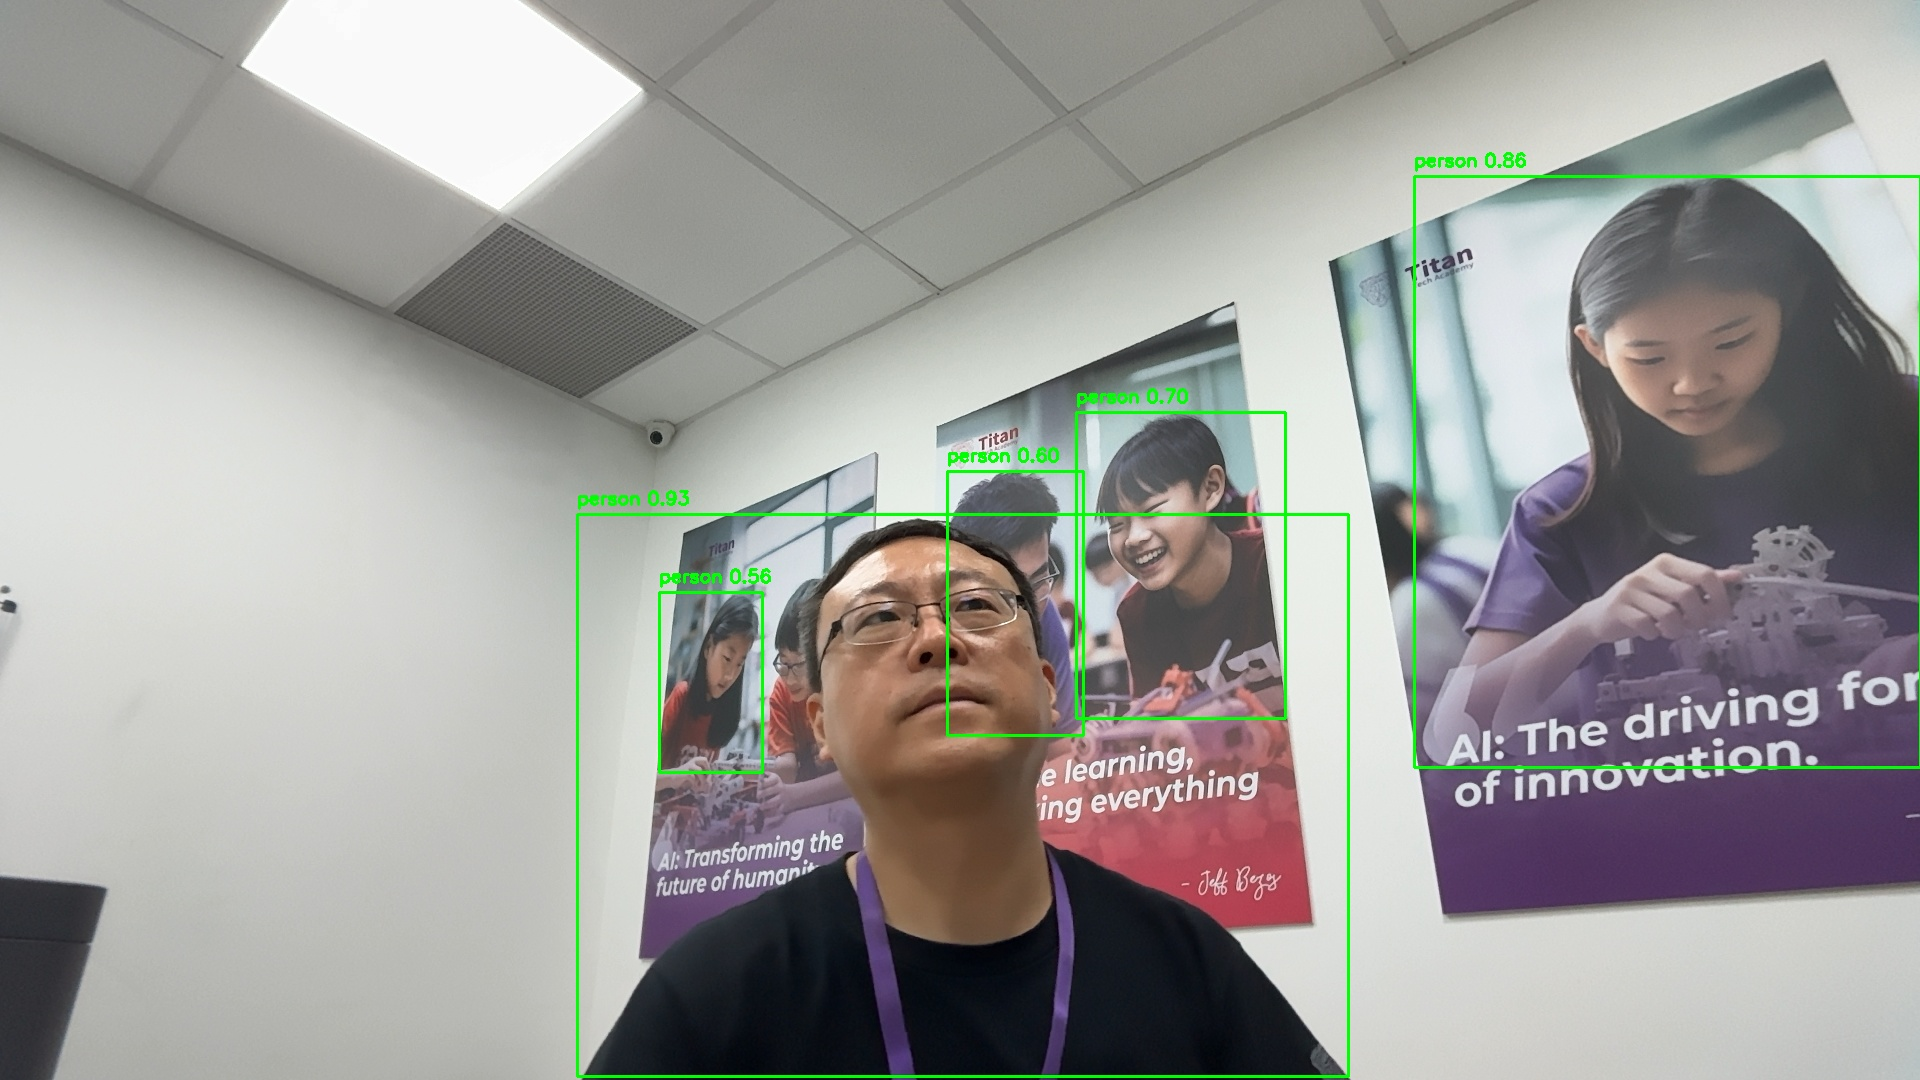

In [18]:
# open camera
import time
camera = cv2.VideoCapture(0,cv2.CAP_AVFOUNDATION)
time.sleep(1)
print("Camera is ready.")

# check for camera
if not camera.isOpened():
    print("The camera is not opened,please check again.")
else:
    print("The camera is on.")
    time.sleep(1)
    
    # check the frame
    handle = None
    start_time=time.time()
    while time.time()-start_time< 5:
        frame_ok,frame=camera.read()
        if not frame_ok:
            continue
        
        # YOLO block
        results = model(frame,verbose = False)
        for box in results[0].boxes:
            class_id = int(box.cls[0])
            name = model.names[class_id]
            conf = float(box.conf[0])
            x1,y1,x2,y2 = map(int,box.xyxy[0])
            cv2.rectangle(frame,(x1,y1),(x2,y2),(0,255,0),2)
            cv2.putText(frame,name,(x1,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2)
            cv2.putText(frame,f"{conf:.2f}",(x1+70,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2)
        
        # show the video
        jpeg_ok,jpeg = cv2.imencode(".jpg",frame)
        if jpeg_ok:
            if handle is None: # create handle
                handle = display(Image(data = jpeg.tobytes()),display_id= True)
            else:
                handle.update(Image(data = jpeg.tobytes()))
        time.sleep(0.02)  
    camera.release()        
        